# Assignment 9
Due Nov. 11

Yazdan Zinati 
260928077   

Dataset with brain atlas A: use the Oasis dataset for classification of male and female
individuals based on brain scans.

In [1]:
import numpy as np
from nilearn import datasets
from nilearn.input_data import NiftiLabelsMasker
from nilearn.image import index_img
import nibabel as nib


def fetch_oasis_dataset(n_rois):
    brain_data = datasets.fetch_oasis_vbm(n_subjects=100)
    yeo = datasets.fetch_atlas_schaefer_2018(
        n_rois=n_rois
    )  # this needs to be modified for some tasks
    print(
        "%i regions found in this atlas"
        % (len(np.unique(nib.load(yeo.maps).get_fdata().ravel())) - 1)
    )
    masker = NiftiLabelsMasker(
        labels_img=yeo.maps, standardize=True, memory="nilearn_cache"
    )
    input_variables = masker.fit_transform(brain_data.gray_matter_maps)
    output_variable = np.array(
        brain_data.ext_vars.mf == "F", dtype=int
    )  # gives 1 for females and 0 for males

    return input_variables, output_variable

Task 1- Benchmark model depth. Use
sklearn.neural_network.MLPClassifier(hidden_layer_sizes=(10,), activation=’relu’) to fit
deep neural network classifiers (DNNs) based on the lowest resolution data (100 ROIs
(n_rois)) using the first 90 subjects as the training set. Fit 5 different DNNs with increasingly
deeper latent representations: (10,), (10, 10), (10, 10, 10), (10, 10, 10, 10), and (10, 10, 10,
10, 10), and train/evaluate each of these architectures using different values for alpha
(0.0001 / 0.001 / 0.01 / 0.1 / 1.0). Next, evaluate each fitted DNNs model on the unseen last
10 subjects. Please plot the classification accuracy on the training set and the test set (x
axis=5 different depths of the DNN architectures, y axis=prediction accuracy, 5 line with 5
colors based on alpha=0.0001 / 0.001 / 0.01 / 0.1 / 1.0; separate plots for train and test).

100 regions found in this atlas


/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/

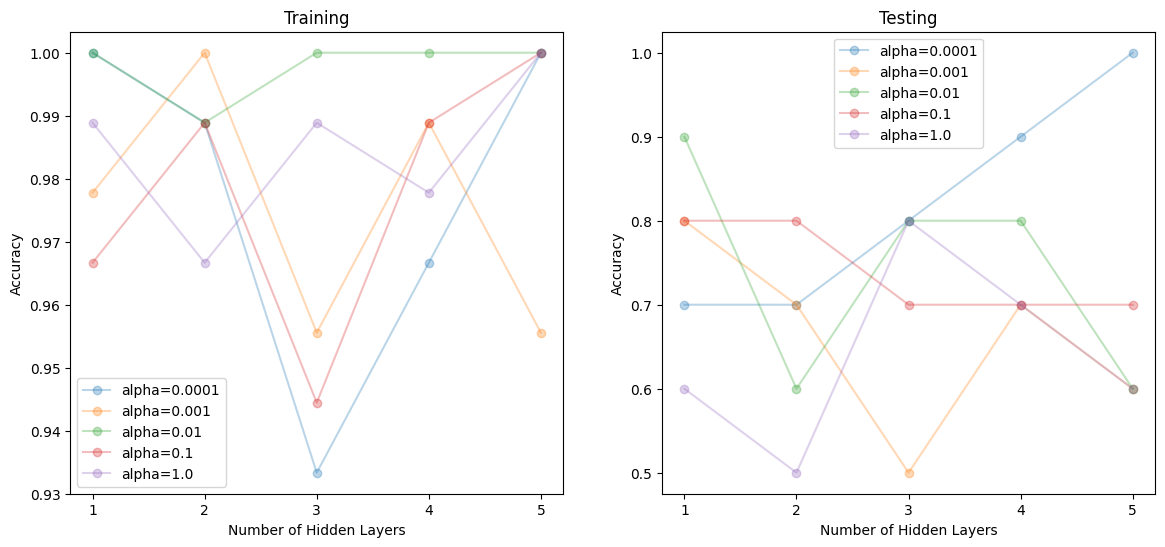

In [2]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt


n_rois = 100
layer_sizes = [(10,), (10, 10), (10, 10, 10), (10, 10, 10, 10), (10, 10, 10, 10, 10)]
alphas = [0.0001, 0.001, 0.01, 0.1, 1.0]

# Fetch data and split into training and testing sets
X, y = fetch_oasis_dataset(n_rois)
X_train, X_test = X[:90], X[90:]
y_train, y_test = y[:90], y[90:]

# create empty np arrays to store results
train_accuracies = np.zeros((len(layer_sizes), len(alphas)))
test_accuracies = np.zeros((len(layer_sizes), len(alphas)))

for i, layers in enumerate(layer_sizes):
    for j, alpha in enumerate(alphas):
        model = MLPClassifier(hidden_layer_sizes=layers, activation="relu", alpha=alpha)
        model.fit(X_train, y_train)
        train_accuracies[i, j] = accuracy_score(y_train, model.predict(X_train))
        test_accuracies[i, j] = accuracy_score(y_test, model.predict(X_test))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# For train set
for j, alpha in enumerate(alphas):
    ax1.plot(
        range(1, 6),
        train_accuracies[:, j],
        marker="o",
        label=f"alpha={alpha}",
        alpha=0.3,
    )
ax1.set_title("Training")
ax1.set_xlabel("Number of Hidden Layers")
ax1.set_ylabel("Accuracy")
ax1.set_xticks(range(1, 6))
ax1.set_xticklabels([str(len(layers)) for layers in layer_sizes])
ax1.legend()

# For test set
for j, alpha in enumerate(alphas):
    ax2.plot(
        range(1, 6),
        test_accuracies[:, j],
        marker="o",
        label=f"alpha={alpha}",
        alpha=0.3,
    )
ax2.set_title("Testing")
ax2.set_xlabel("Number of Hidden Layers")
ax2.set_ylabel("Accuracy")
ax2.set_xticks(range(1, 6))
ax2.set_xticklabels([str(len(layers)) for layers in layer_sizes])
ax2.legend()

plt.show()

Task 2- Benchmark model width. Use
sklearn.neural_network.MLPClassifier(hidden_layer_sizes=(10,), activation=’relu’) to fit
deep neural network classifiers (DNNs) based on the lowest resolution data (100 ROIs
(n_rois)) using the first 90 subjects as the training set. Fit 5 different DNNs with increasingly
wide latent representations: (5,), (10), (25), (50), and (100). Next, evaluate each fitted DNNs
model on the unseen last 10 subjects. Please plot the classification accuracy on the
training set and the test set (x axis=5 different widths of the DNN architectures, y
axis=prediction accuracy, 5 line with 5 colors based on alpha=0.0001 / 0.001 / 0.01 / 0.1 /
1.0; separate plots for train and test).

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/

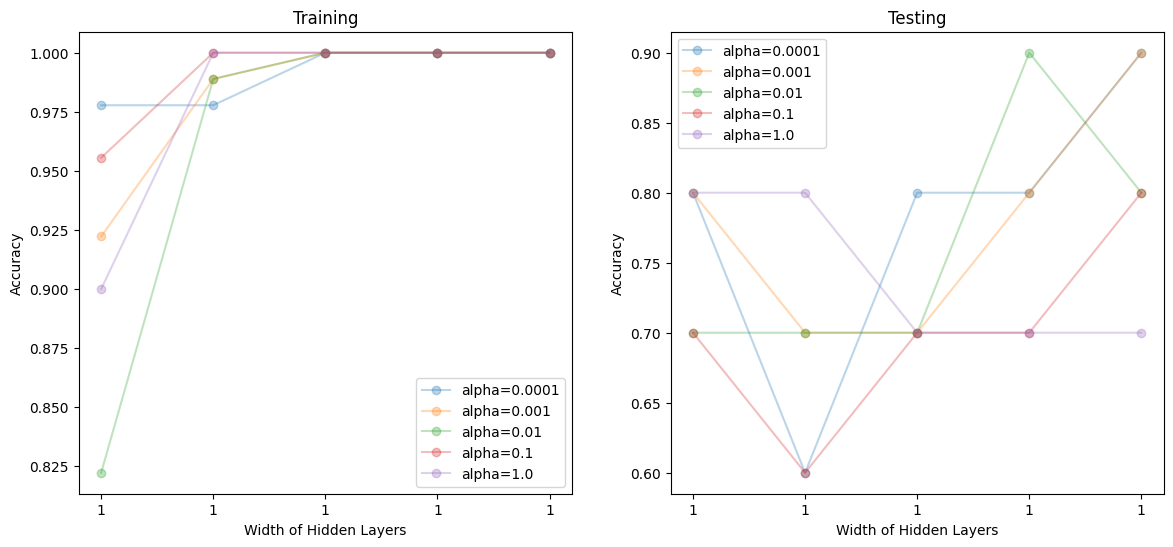

In [3]:
layer_widths = [(5,), (10,), (25,), (50,), (100,)]

# create empty np arrays to store results
train_accuracies = np.zeros((len(layer_widths), len(alphas)))
test_accuracies = np.zeros((len(layer_widths), len(alphas)))

for i, layers in enumerate(layer_widths):
    for j, alpha in enumerate(alphas):
        model = MLPClassifier(hidden_layer_sizes=layers, activation="relu", alpha=alpha)
        model.fit(X_train, y_train)
        train_accuracies[i, j] = accuracy_score(y_train, model.predict(X_train))
        test_accuracies[i, j] = accuracy_score(y_test, model.predict(X_test))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# For train set
for j, alpha in enumerate(alphas):
    ax1.plot(
        range(1, 6),
        train_accuracies[:, j],
        marker="o",
        label=f"alpha={alpha}",
        alpha=0.3,
    )
ax1.set_title("Training")
ax1.set_xlabel("Width of Hidden Layers")
ax1.set_ylabel("Accuracy")
ax1.set_xticks(range(1, 6))
ax1.set_xticklabels([str(len(layers)) for layers in layer_widths])
ax1.legend()

# For test set
for j, alpha in enumerate(alphas):
    ax2.plot(
        range(1, 6),
        test_accuracies[:, j],
        marker="o",
        label=f"alpha={alpha}",
        alpha=0.3,
    )
ax2.set_title("Testing")
ax2.set_xlabel("Width of Hidden Layers")
ax2.set_ylabel("Accuracy")
ax2.set_xticks(range(1, 6))
ax2.set_xticklabels([str(len(layers)) for layers in layer_widths])
ax2.legend()

plt.show()

Task 3- Benchmark model with different types of non-linearity. Use
sklearn.neural_network.MLPClassifier(hidden_layer_sizes=(10,), activation=’relu’) to fit
deep neural network classifiers (DNNs) based on the lowest resolution data (100 ROIs
(n_rois)) using the first 90 subjects as the training set. Fit 5 different DNNs with latent
representations based on different kinds of non-linear transformation in the hidden layers of
the model: activation=’identity’, ‘logistic’, ‘tanh’, and ‘relu’. Next, evaluate each fitted DNNsmodel on the unseen last 10% of the structural brain scans. Please plot the classification
accuracy on the training set and the test set (x axis=4 different activation functions of the
DNN architectures, y axis=prediction accuracy, 5 lines with 5 colors based on alpha=0.0001
/ 0.001 / 0.01 / 0.1 / 1.0; separate plots for train and test).

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/

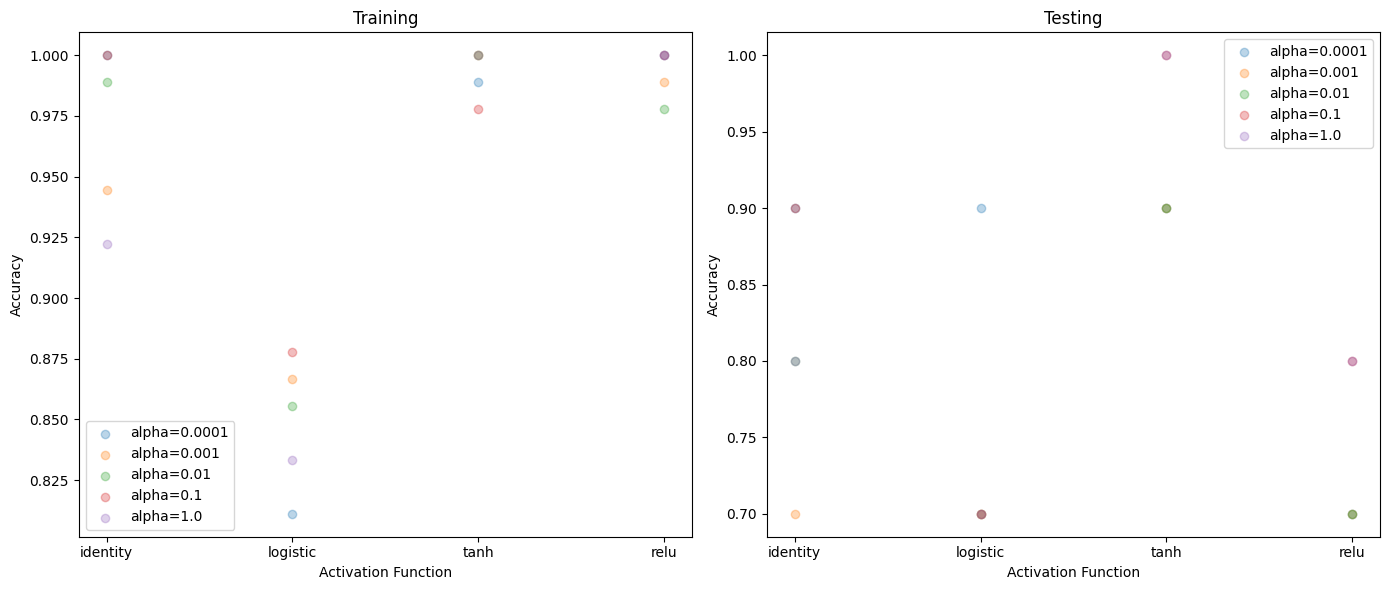

In [4]:
activations = ["identity", "logistic", "tanh", "relu"]

train_accuracies = np.zeros((len(activations), len(alphas)))
test_accuracies = np.zeros((len(activations), len(alphas)))

for i, activation in enumerate(activations):
    for j, alpha in enumerate(alphas):
        model = MLPClassifier(
            hidden_layer_sizes=(10,), activation=activation, alpha=alpha
        )
        model.fit(X_train, y_train)

        # Training and testing accuracies
        train_accuracies[i, j] = accuracy_score(y_train, model.predict(X_train))
        test_accuracies[i, j] = accuracy_score(y_test, model.predict(X_test))

# Step 4: Plot the results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot for training set accuracy
for j, alpha in enumerate(alphas):
    ax1.scatter(
        range(1, 5),
        train_accuracies[:, j],
        marker="o",
        label=f"alpha={alpha}",
        alpha=0.3,
    )
ax1.set_title("Training")
ax1.set_xlabel("Activation Function")
ax1.set_ylabel("Accuracy")
ax1.set_xticks(range(1, 5))
ax1.set_xticklabels(activations)
ax1.legend()

# Plot for testing set accuracy
for j, alpha in enumerate(alphas):
    ax2.scatter(
        range(1, 5),
        test_accuracies[:, j],
        marker="o",
        label=f"alpha={alpha}",
        alpha=0.3,
    )
ax2.set_title("Testing")
ax2.set_xlabel("Activation Function")
ax2.set_ylabel("Accuracy")
ax2.set_xticks(range(1, 5))
ax2.set_xticklabels(activations)
ax2.legend()

plt.tight_layout()
plt.show()

Task 4- Same as task 1. But using alpha=0.0001 throughout. Instead, use
random_state=0...99 (random_state of the MLP model) to produce 100 lines from 100
repetitions of the same modeling approach with these different random initalizations.

100 regions found in this atlas


/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/

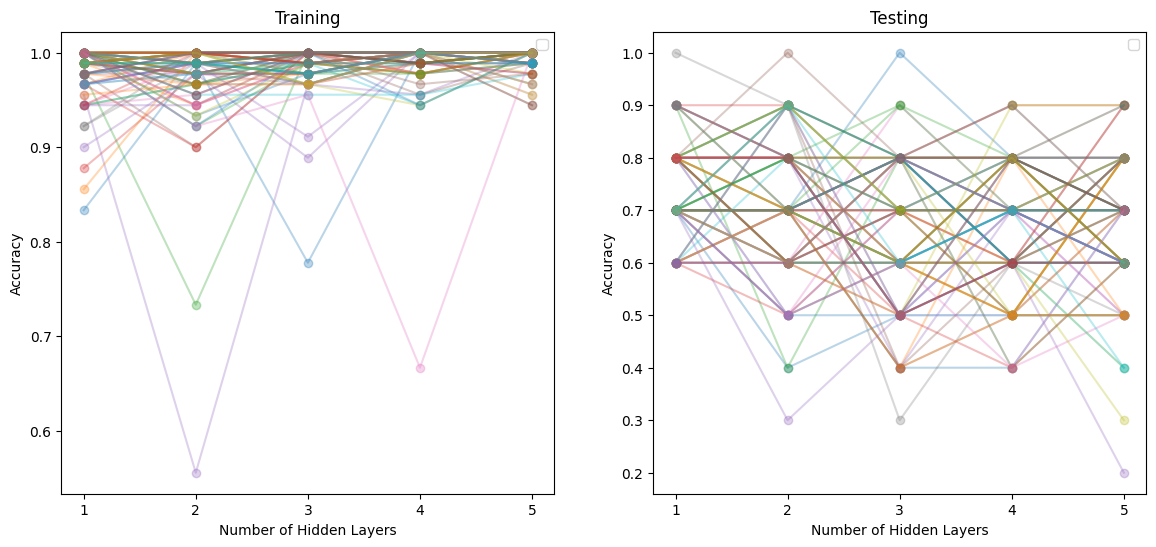

In [5]:
n_rois = 100
layer_sizes = [(10,), (10, 10), (10, 10, 10), (10, 10, 10, 10), (10, 10, 10, 10, 10)]
alpha = 0.0001
random_states = range(100)

# Fetch data and split into training and testing sets
X, y = fetch_oasis_dataset(n_rois)
X_train, X_test = X[:90], X[90:]
y_train, y_test = y[:90], y[90:]

# create empty np arrays to store results
train_accuracies = np.zeros((len(layer_sizes), len(random_states)))
test_accuracies = np.zeros((len(layer_sizes), len(random_states)))

for i, layers in enumerate(layer_sizes):
    for j, radom_state in enumerate(random_states):
        model = MLPClassifier(
            hidden_layer_sizes=layers,
            activation="relu",
            alpha=alpha,
            random_state=radom_state,
        )
        model.fit(X_train, y_train)
        train_accuracies[i, j] = accuracy_score(y_train, model.predict(X_train))
        test_accuracies[i, j] = accuracy_score(y_test, model.predict(X_test))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# For train set
for j, random_state in enumerate(random_states):
    ax1.plot(range(1, 6), train_accuracies[:, j], marker="o", alpha=0.3)
ax1.set_title("Training")
ax1.set_xlabel("Number of Hidden Layers")
ax1.set_ylabel("Accuracy")
ax1.set_xticks(range(1, 6))
ax1.set_xticklabels([str(len(layers)) for layers in layer_sizes])
ax1.legend()

# For test set
for j, random_state in enumerate(random_states):
    ax2.plot(range(1, 6), test_accuracies[:, j], marker="o", alpha=0.3)
ax2.set_title("Testing")
ax2.set_xlabel("Number of Hidden Layers")
ax2.set_ylabel("Accuracy")
ax2.set_xticks(range(1, 6))
ax2.set_xticklabels([str(len(layers)) for layers in layer_sizes])
ax2.legend()

plt.show()

Task 5- Calibration plot: Like task 3 but using alpha=0.0001 throughout and k-fold k=10
cross-validation on 100 brain regions to produce a calibration plot (requires predict_proba()
function, implemented in sklearn) for the four activation functions. Compare these
calibration curves to that of LogisticRegression (default parameters) but also plotting its
calibration curve based on the same cross-validation scheme

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/

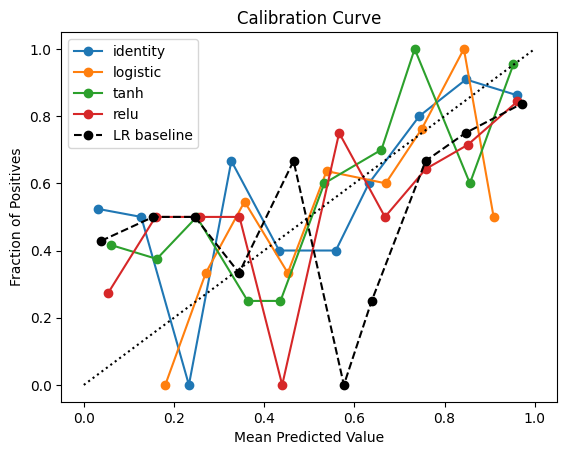

In [6]:
from sklearn.calibration import calibration_curve
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression

k = 10
cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

plt.figure()
for activation in activations:
    model = MLPClassifier(hidden_layer_sizes=(10,), activation=activation, alpha=alpha)
    probas_nn = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[
        :, 1
    ]  # Get probability of class 1

    fraction_of_positives, mean_predicted_value = calibration_curve(
        y, probas_nn, n_bins=10
    )
    plt.plot(mean_predicted_value, fraction_of_positives, marker="o", label=activation)


# baseline LR
log_reg = LogisticRegression()
probas_lr = cross_val_predict(log_reg, X, y, cv=cv, method="predict_proba")[:, 1]

# Generate calibration curve for Logistic Regression
fraction_of_positives_lr, mean_predicted_value_lr = calibration_curve(
    y, probas_lr, n_bins=10
)
plt.plot(
    mean_predicted_value_lr,
    fraction_of_positives_lr,
    marker="o",
    label="LR baseline",
    linestyle="--",
    color="black",
)

# Perfect Calibration (diagonal line)
plt.plot([0, 1], [0, 1], "k:")
plt.title("Calibration Curve")
plt.xlabel("Mean Predicted Value")
plt.ylabel("Fraction of Positives")
plt.legend(loc="best")
plt.show()

Dataset with brain atlas B: use the Oasis dataset to predict a continuous outcome (age)
from structural brain scans

In [7]:
import os

from sklearn.preprocessing import StandardScaler


def load_craddock_local(base_path):
    # Dictionary to hold the dataset information
    craddock_data = {
        "scorr_mean": os.path.join(base_path, "scorr05_mean_all.nii.gz"),
        "tcorr_mean": os.path.join(base_path, "tcorr05_mean_all.nii.gz"),
        "scorr_2level": os.path.join(base_path, "scorr05_2level_all.nii.gz"),
        "tcorr_2level": os.path.join(base_path, "tcorr05_2level_all.nii.gz"),
        "random": os.path.join(base_path, "random_all.nii.gz"),
        "description": "Craddock 2012 atlas parcellation dataset emphasizing spatial and temporal homogeneity.",
    }
    return craddock_data


def fetch_second_dataset(n_rois, debug=False):

    brain_data = datasets.fetch_oasis_vbm(n_subjects=100)

    brain_data_dir = "/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/A3/craddock/"
    crad = load_craddock_local(brain_data_dir)

    atlas_nii = index_img(crad["scorr_mean"], n_rois)
    masker = NiftiLabelsMasker(labels_img=atlas_nii, standardize=True)
    input_variables = masker.fit_transform(brain_data.gray_matter_maps)
    output_variable = StandardScaler().fit_transform(brain_data.ext_vars.age[:, None])[
        :, 0
    ]  # gives subject age on standard units after z-scoring
    return input_variables, output_variable

6- analogous to task 1 but predicting continuous subject age (using MLPRegressor instead)
and using the lowest resolution of Craddock region atlas resolution (.scorr_mean). Use R2
coefficient of determination instead of classification accuracy, which can be found at
sklearn.metrics.r2_score.

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/

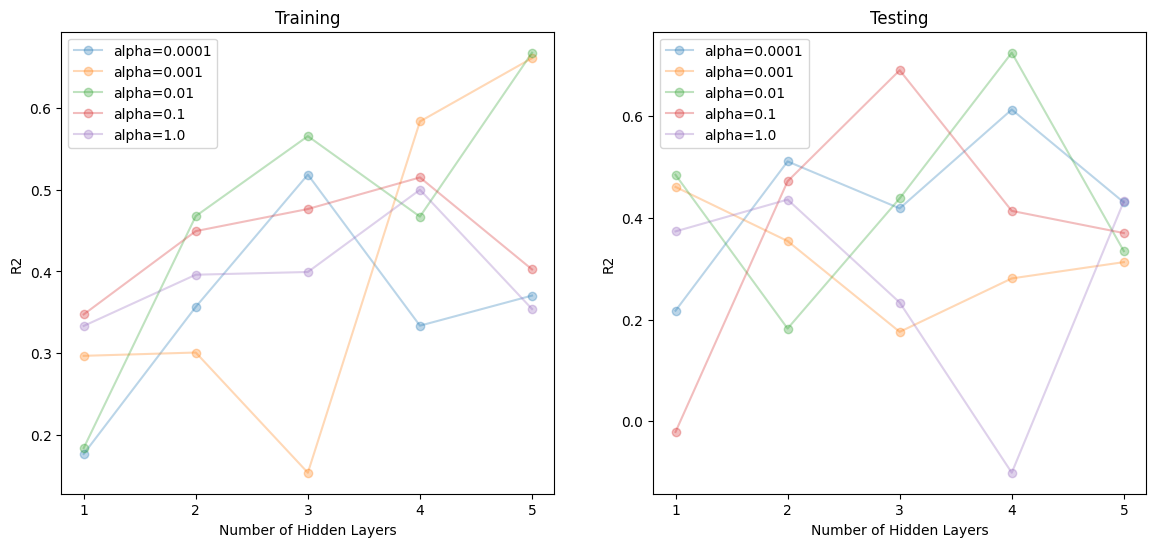

In [8]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score


n_rois = 0
layer_sizes = [(10,), (10, 10), (10, 10, 10), (10, 10, 10, 10), (10, 10, 10, 10, 10)]
alphas = [0.0001, 0.001, 0.01, 0.1, 1.0]

# Fetch data and split into training and testing sets
X, y = fetch_second_dataset(n_rois)
X_train, X_test = X[:90], X[90:]
y_train, y_test = y[:90], y[90:]

# create empty np arrays to store results
train_accuracies = np.zeros((len(layer_sizes), len(alphas)))
test_accuracies = np.zeros((len(layer_sizes), len(alphas)))

for i, layers in enumerate(layer_sizes):
    for j, alpha in enumerate(alphas):
        model = MLPRegressor(hidden_layer_sizes=layers, activation="relu", alpha=alpha)
        model.fit(X_train, y_train)
        train_accuracies[i, j] = r2_score(y_train, model.predict(X_train))
        test_accuracies[i, j] = r2_score(y_test, model.predict(X_test))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# For train set
for j, alpha in enumerate(alphas):
    ax1.plot(
        range(1, 6),
        train_accuracies[:, j],
        marker="o",
        label=f"alpha={alpha}",
        alpha=0.3,
    )
ax1.set_title("Training")
ax1.set_xlabel("Number of Hidden Layers")
ax1.set_ylabel("R2")
ax1.set_xticks(range(1, 6))
ax1.set_xticklabels([str(len(layers)) for layers in layer_sizes])
ax1.legend()

# For test set
for j, alpha in enumerate(alphas):
    ax2.plot(
        range(1, 6),
        test_accuracies[:, j],
        marker="o",
        label=f"alpha={alpha}",
        alpha=0.3,
    )
ax2.set_title("Testing")
ax2.set_xlabel("Number of Hidden Layers")
ax2.set_ylabel("R2")
ax2.set_xticks(range(1, 6))
ax2.set_xticklabels([str(len(layers)) for layers in layer_sizes])
ax2.legend()

plt.show()

7- analogous to task 2 but predicting continuous subject age and using the lowest resolution
version of Craddock region atlas resolution. Use R2 coefficient of determination instead of
classification accuracy.

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/

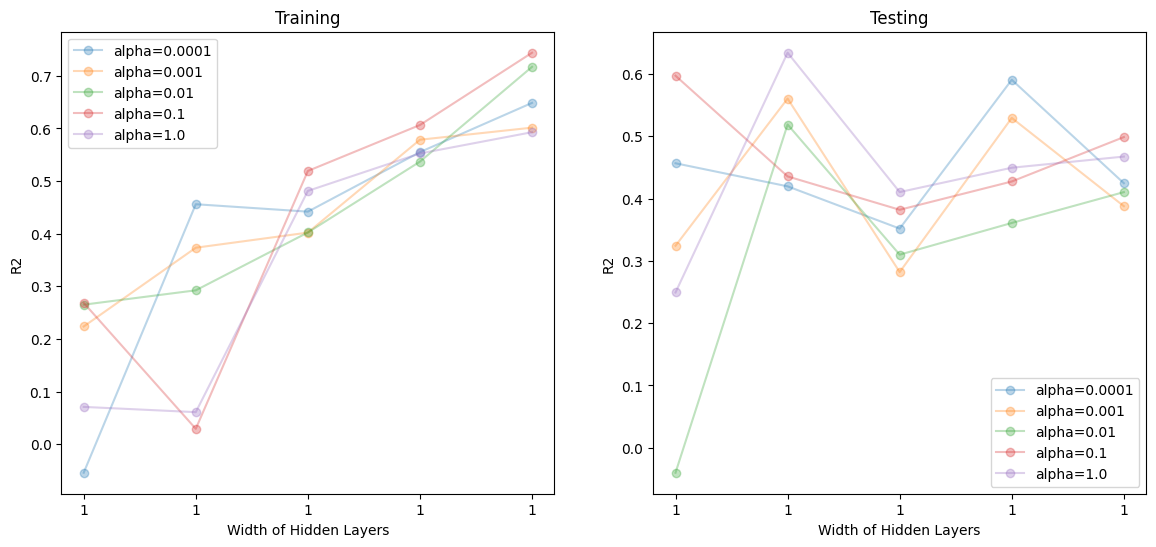

In [9]:
layer_widths = [(5,), (10,), (25,), (50,), (100,)]

# create empty np arrays to store results
train_accuracies = np.zeros((len(layer_widths), len(alphas)))
test_accuracies = np.zeros((len(layer_widths), len(alphas)))

for i, layers in enumerate(layer_widths):
    for j, alpha in enumerate(alphas):
        model = MLPRegressor(hidden_layer_sizes=layers, activation="relu", alpha=alpha)
        model.fit(X_train, y_train)
        train_accuracies[i, j] = r2_score(y_train, model.predict(X_train))
        test_accuracies[i, j] = r2_score(y_test, model.predict(X_test))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# For train set
for j, alpha in enumerate(alphas):
    ax1.plot(
        range(1, 6),
        train_accuracies[:, j],
        marker="o",
        label=f"alpha={alpha}",
        alpha=0.3,
    )
ax1.set_title("Training")
ax1.set_xlabel("Width of Hidden Layers")
ax1.set_ylabel("R2")
ax1.set_xticks(range(1, 6))
ax1.set_xticklabels([str(len(layers)) for layers in layer_widths])
ax1.legend()

# For test set
for j, alpha in enumerate(alphas):
    ax2.plot(
        range(1, 6),
        test_accuracies[:, j],
        marker="o",
        label=f"alpha={alpha}",
        alpha=0.3,
    )
ax2.set_title("Testing")
ax2.set_xlabel("Width of Hidden Layers")
ax2.set_ylabel("R2")
ax2.set_xticks(range(1, 6))
ax2.set_xticklabels([str(len(layers)) for layers in layer_widths])
ax2.legend()

plt.show()

8- analogous to task 3 but plotting the R2 coefficient instead of accuracy.

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/

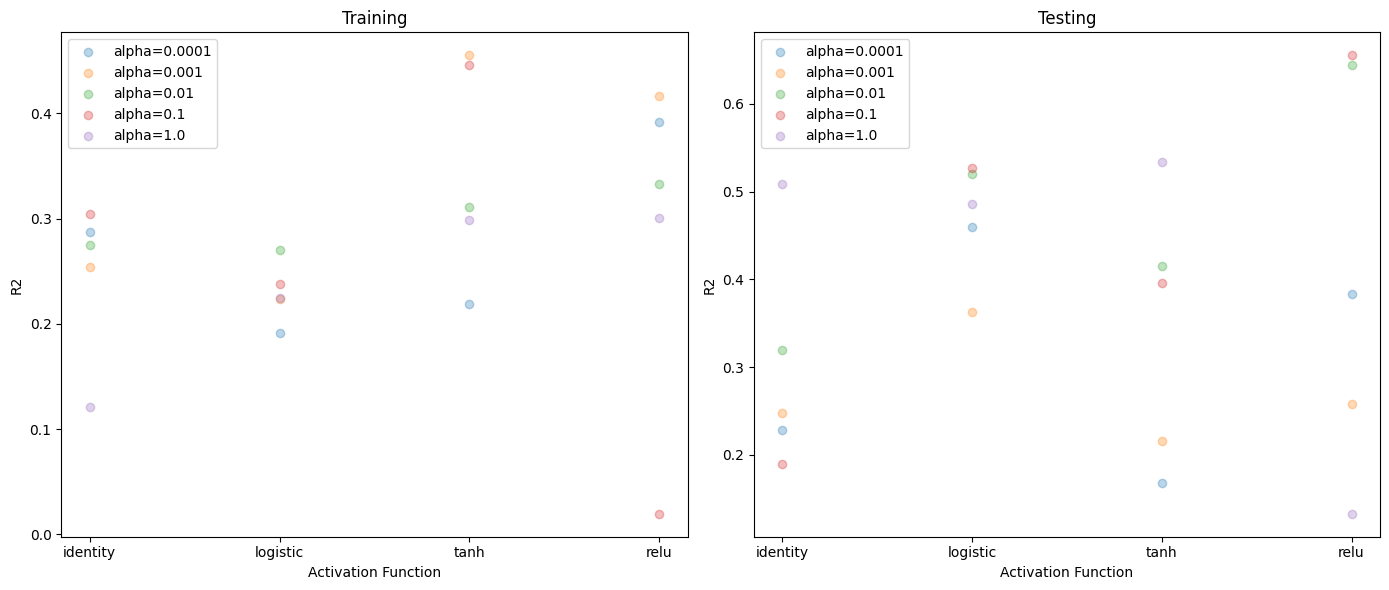

In [10]:
activations = ["identity", "logistic", "tanh", "relu"]

train_accuracies = np.zeros((len(activations), len(alphas)))
test_accuracies = np.zeros((len(activations), len(alphas)))

for i, activation in enumerate(activations):
    for j, alpha in enumerate(alphas):
        model = MLPRegressor(
            hidden_layer_sizes=(10,), activation=activation, alpha=alpha
        )
        model.fit(X_train, y_train)

        # Training and testing accuracies
        train_accuracies[i, j] = r2_score(y_train, model.predict(X_train))
        test_accuracies[i, j] = r2_score(y_test, model.predict(X_test))

# Step 4: Plot the results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot for training set accuracy
for j, alpha in enumerate(alphas):
    ax1.scatter(
        range(1, 5),
        train_accuracies[:, j],
        marker="o",
        label=f"alpha={alpha}",
        alpha=0.3,
    )
ax1.set_title("Training")
ax1.set_xlabel("Activation Function")
ax1.set_ylabel("R2")
ax1.set_xticks(range(1, 5))
ax1.set_xticklabels(activations)
ax1.legend()

# Plot for testing set accuracy
for j, alpha in enumerate(alphas):
    ax2.scatter(
        range(1, 5),
        test_accuracies[:, j],
        marker="o",
        label=f"alpha={alpha}",
        alpha=0.3,
    )
ax2.set_title("Testing")
ax2.set_xlabel("Activation Function")
ax2.set_ylabel("R2")
ax2.set_xticks(range(1, 5))
ax2.set_xticklabels(activations)
ax2.legend()

plt.tight_layout()
plt.show()

9- analogous to task 4

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/

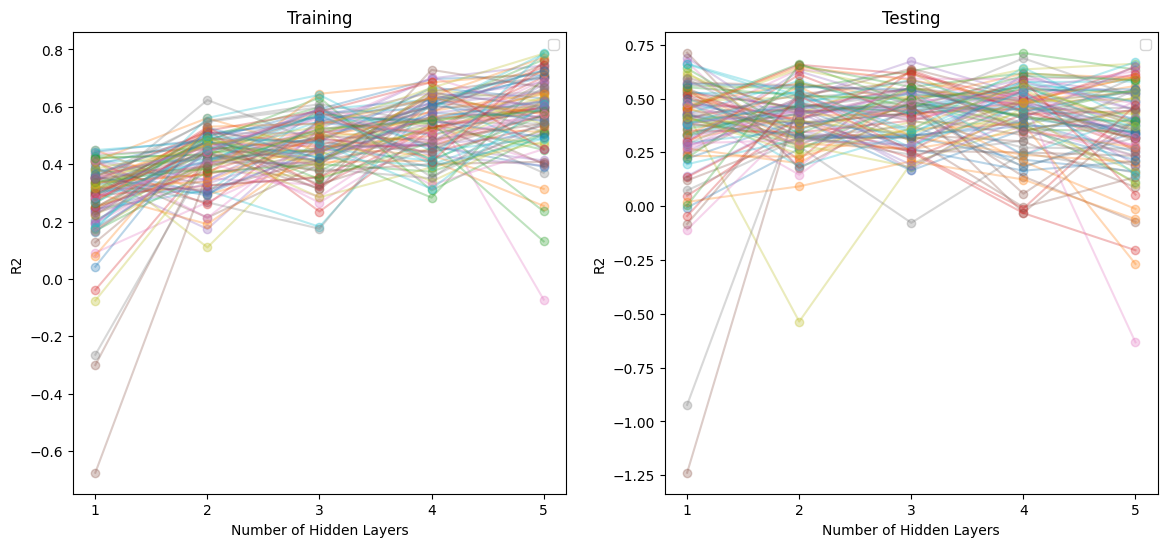

In [11]:
layer_sizes = [(10,), (10, 10), (10, 10, 10), (10, 10, 10, 10), (10, 10, 10, 10, 10)]
alpha = 0.0001
random_states = range(100)

# create empty np arrays to store results
train_accuracies = np.zeros((len(layer_sizes), len(random_states)))
test_accuracies = np.zeros((len(layer_sizes), len(random_states)))

for i, layers in enumerate(layer_sizes):
    for j, radom_state in enumerate(random_states):
        model = MLPRegressor(
            hidden_layer_sizes=layers,
            activation="relu",
            alpha=alpha,
            random_state=radom_state,
        )
        model.fit(X_train, y_train)
        train_accuracies[i, j] = r2_score(y_train, model.predict(X_train))
        test_accuracies[i, j] = r2_score(y_test, model.predict(X_test))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# For train set
for j, random_state in enumerate(random_states):
    ax1.plot(range(1, 6), train_accuracies[:, j], marker="o", alpha=0.3)
ax1.set_title("Training")
ax1.set_xlabel("Number of Hidden Layers")
ax1.set_ylabel("R2")
ax1.set_xticks(range(1, 6))
ax1.set_xticklabels([str(len(layers)) for layers in layer_sizes])
ax1.legend()

# For test set
for j, random_state in enumerate(random_states):
    ax2.plot(range(1, 6), test_accuracies[:, j], marker="o", alpha=0.3)
ax2.set_title("Testing")
ax2.set_xlabel("Number of Hidden Layers")
ax2.set_ylabel("R2")
ax2.set_xticks(range(1, 6))
ax2.set_xticklabels([str(len(layers)) for layers in layer_sizes])
ax2.legend()

plt.show()

10- Predict subject age using a MLPRegressor and training routine that is analogous to task
5. Groups the subjects into 10 bins based on age (bins of size ([max age] - [min age])/10),
then for subjects in each age bin calculate the mean squared error (MSE) between the true
and predicted ages, across the 10 folds. Plot the MSE vs age bin (10 age bins on the x-axis,
mean MSE across subjects in that age bin on the y-axis). For each age bin there should
only be one point (the mean of predicted age MSE across subjects in that age bin).

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/yazdan/

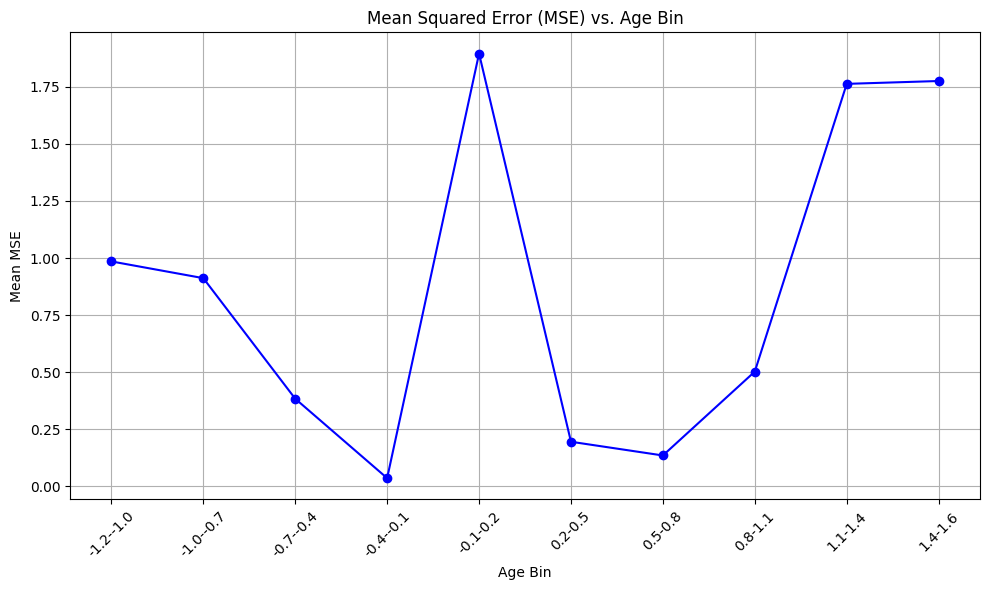

In [12]:
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold

cv = KFold(n_splits=10, shuffle=True, random_state=42)

model = MLPRegressor(hidden_layer_sizes=(10,), activation="relu", alpha=0.0001)
predicted_ages = cross_val_predict(model, X, y, cv=cv)

min_age, max_age = y.min(), y.max()
age_bins = np.linspace(min_age, max_age, 11)
bin_indices = np.digitize(y, bins=age_bins) - 1

# Calculate mean MSE for each bin
mse_per_bin = []
for i in range(10):
    bin_mask = bin_indices == i
    if np.any(bin_mask):
        mse = mean_squared_error(y[bin_mask], predicted_ages[bin_mask])
        mse_per_bin.append(mse)
    else:
        mse_per_bin.append(np.nan)  # Handle empty bins
        print("Error - can't bin")

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), mse_per_bin, marker="o", color="b")
plt.title("Mean Squared Error (MSE) vs. Age Bin")
plt.xlabel("Age Bin")
plt.ylabel("Mean MSE")
plt.xticks(
    range(1, 11),
    [f"{age_bins[i]:.1f}-{age_bins[i+1]:.1f}" for i in range(10)],
    rotation=45,
)
plt.grid(True)
plt.tight_layout()
plt.show()